# Sentiment Analysis on US Airline Tweets
### Final Project — Natural Language Processing (NLP)

**By:** Eunice Agogo  

---

## Project Overview

In this project, we perform **sentiment analysis** on a real-world Twitter dataset containing tweets about major US airlines.  
The goal is to classify each tweet as **Positive**, **Negative**, or **Neutral** using several NLP techniques and machine learning models.

We follow the full NLP workflow:
1. Data Collection & Exploration
2. Preprocessing
3. Feature Extraction (BoW, TF-IDF, Word Embeddings)
4. Model Training (Logistic Regression, SVM, and a Transformer-based model)
5. Evaluation (Accuracy, Precision, Recall, F1-Score)
6. Analysis & Discussion

---

> **Revision note:** the narrative cells (Section 3.3 note, Section 6 and the final summary) were revised after the course submission so that every statement matches the measured outputs in this notebook. The code and results are unchanged.

---


## Step 0 — Install & Import Required Libraries

We start by importing all the Python libraries we will need throughout this notebook.  
These libraries handle everything from data manipulation, to text processing, to model training and evaluation.

| Library | Purpose |
|---|---|
| `pandas` | Load and manipulate our CSV dataset |
| `numpy` | Numerical operations |
| `matplotlib` / `seaborn` | Data visualization |
| `nltk` | Text preprocessing (tokenization, stopwords, lemmatization) |
| `sklearn` | Feature extraction and ML models |
| `transformers` | Pre-trained BERT model for advanced classification |
| `wordcloud` | Generate word cloud visualizations |

In [3]:
# ── Install any missing packages (run once) ──────────────────────────────────
# Uncomment the line below if running for the first time
# !pip install transformers torch wordcloud

# ── Standard libraries ───────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# ── Text preprocessing ───────────────────────────────────────────────────────
import re
import string
import nltk
nltk.download('stopwords',    quiet=True)
nltk.download('punkt',        quiet=True)
nltk.download('punkt_tab',    quiet=True)
nltk.download('wordnet',      quiet=True)
nltk.download('omw-1.4',      quiet=True)
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# ── Feature extraction ───────────────────────────────────────────────────────
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# ── Machine learning models ──────────────────────────────────────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline

# ── Model evaluation ─────────────────────────────────────────────────────────
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report,
                              confusion_matrix, ConfusionMatrixDisplay)

# ── Word cloud ───────────────────────────────────────────────────────────────
from wordcloud import WordCloud

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


---
## Step 1 — Data Collection & Exploration

### About the Dataset
We use the **Twitter US Airline Sentiment** dataset, which was collected in February 2015.  
It contains **14,640 tweets** directed at 6 major US airlines (United, Delta, American, Southwest, US Airways, Virgin America).

Each tweet was manually labelled as:
- **Positive** — the passenger had a good experience
- **Negative** — the passenger was unhappy (the majority class)
- **Neutral** — the tweet is neither clearly positive nor negative

This is a great real-world dataset because it includes typical social media challenges:  
sarcasm, slang, hashtags, @mentions, and informal language.

We will only use two columns:
- `text` → the raw tweet content
- `airline_sentiment` → the label (positive / negative / neutral)

In [4]:
# ── Load the dataset ─────────────────────────────────────────────────────────
from google.colab import files
uploaded = files.upload()

df = pd.read_csv("Tweets.csv")

print(f"Dataset Shape: {df.shape[0]} rows × {df.shape[1]} columns")
print("Column names:", df.columns.tolist())

Saving Tweets.csv to Tweets.csv
Dataset Shape: 14640 rows × 15 columns
Column names: ['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone']


In [5]:
# ── Keep only the columns we need ────────────────────────────────────────────
df = df[['text', 'airline_sentiment']].copy()
df.columns = ['text', 'sentiment']   # rename for clarity

# Preview the first 5 rows
df.head()

,text,sentiment
0,@VirginAmerica What @dhepburn said.,neutral
1,@VirginAmerica plus you've added commercials t...,positive
2,@VirginAmerica I didn't today... Must mean I n...,neutral
3,@VirginAmerica it's really aggressive to blast...,negative
4,@VirginAmerica and it's a really big bad thing...,negative


In [6]:
# ── Check for missing values ──────────────────────────────────────────────────
print("Missing values per column:")
print(df.isnull().sum())

# Drop rows with missing text (if any)
df.dropna(subset=['text', 'sentiment'], inplace=True)
print(f"\nClean dataset size: {len(df)} rows")

Missing values per column:
text         0
sentiment    0
dtype: int64

Clean dataset size: 14640 rows


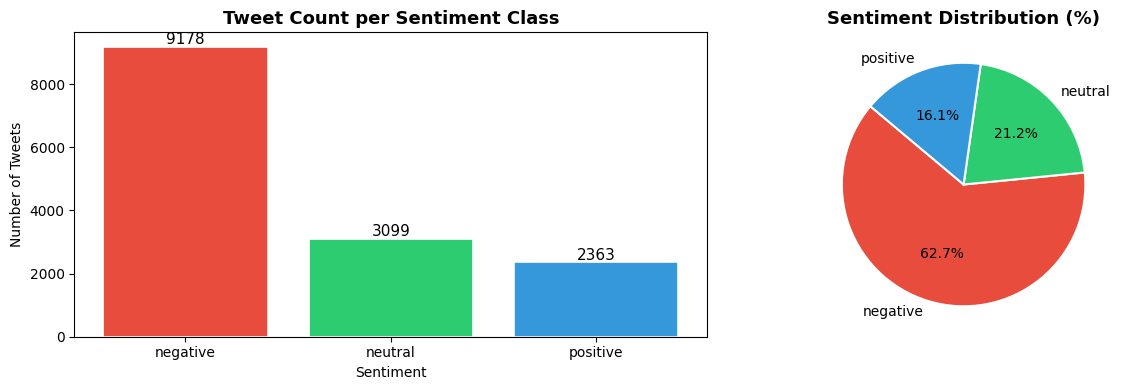


 Key observation:
The dataset is IMBALANCED — negative tweets make up ~63% of all data.
This is common in customer-service Twitter data; people tweet more when unhappy.


In [7]:
# ── Visualise the class distribution ─────────────────────────────────────────
# How many tweets belong to each sentiment class?

counts = df['sentiment'].value_counts()
colors = ['#e74c3c', '#2ecc71', '#3498db']   # red=neg, green=pos, blue=neutral

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Bar chart
axes[0].bar(counts.index, counts.values, color=colors, edgecolor='white', linewidth=1.2)
axes[0].set_title('Tweet Count per Sentiment Class', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Sentiment')
axes[0].set_ylabel('Number of Tweets')
for i, (label, val) in enumerate(zip(counts.index, counts.values)):
    axes[0].text(i, val + 80, str(val), ha='center', fontsize=11)

# Pie chart
axes[1].pie(counts.values, labels=counts.index, colors=colors,
            autopct='%1.1f%%', startangle=140,
            wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
axes[1].set_title('Sentiment Distribution (%)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('class_distribution.png', dpi=120, bbox_inches='tight')
plt.show()

print("\n Key observation:")
print("The dataset is IMBALANCED — negative tweets make up ~63% of all data.")
print("This is common in customer-service Twitter data; people tweet more when unhappy.")

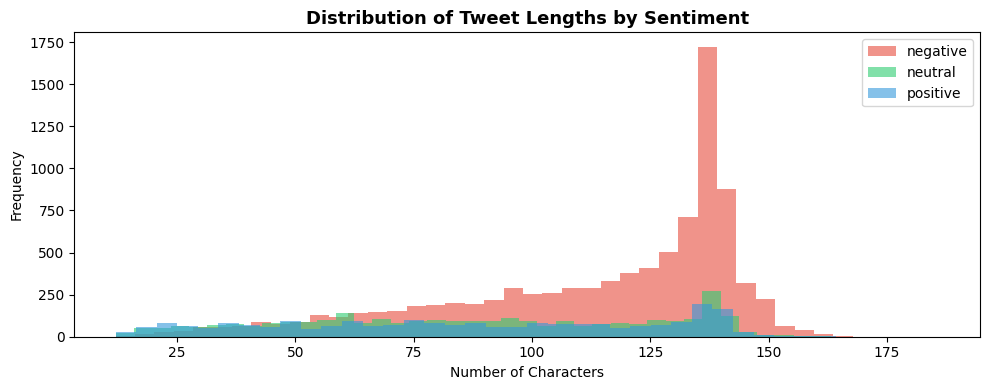

            count   mean   std   min   25%    50%    75%    max
sentiment                                                      
negative   9178.0  113.9  30.7  12.0  96.0  126.0  138.0  176.0
neutral    3099.0   87.4  37.7  12.0  57.0   87.0  123.0  167.0
positive   2363.0   86.1  39.5  12.0  52.0   86.0  124.0  186.0


In [8]:
# ── Explore tweet lengths ─────────────────────────────────────────────────────
# Understanding text length helps us know what we're dealing with

df['tweet_length'] = df['text'].apply(len)

fig, ax = plt.subplots(figsize=(10, 4))
for sentiment, color in zip(['negative', 'neutral', 'positive'], colors):
    subset = df[df['sentiment'] == sentiment]['tweet_length']
    ax.hist(subset, bins=40, alpha=0.6, color=color, label=sentiment)

ax.set_title('Distribution of Tweet Lengths by Sentiment', fontsize=13, fontweight='bold')
ax.set_xlabel('Number of Characters')
ax.set_ylabel('Frequency')
ax.legend()
plt.tight_layout()
plt.savefig('tweet_lengths.png', dpi=120, bbox_inches='tight')
plt.show()

print(df.groupby('sentiment')['tweet_length'].describe().round(1))

---
## Step 2 — Text Preprocessing

Raw tweets are messy! Before feeding text to any machine learning model, we need to **clean and normalise** it.  
We apply the following sub-steps in order:

| Step | What it does | Example |
|---|---|---|
| **Remove @mentions** | e.g. `@VirginAmerica` → removed | Twitter handles carry no sentiment |
| **Remove URLs** | `http://...` → removed | Links add no meaning |
| **Remove hashtags** | `#BadFlight` → `BadFlight` or removed | Keeps word, drops `#` |
| **Lowercasing** | `"GREAT"` → `"great"` | Treats same words consistently |
| **Remove punctuation & numbers** | `"flight!123"` → `"flight"` | Reduces noise |
| **Tokenisation** | `"love this flight"` → `["love", "this", "flight"]` | Splits text into words |
| **Stopword removal** | Remove `"is", "the", "a"`, etc. | These words carry no sentiment |
| **Lemmatisation** | `"running"` → `"run"`, `"better"` → `"good"` | Reduces words to their base form |

> 💡 **Lemmatisation vs Stemming**: Both reduce words to a base form.  
> Lemmatisation is smarter — it uses vocabulary knowledge ("better" → "good").  
> Stemming just chops endings ("running" → "runn"), which can produce non-words.

In [9]:
# ── Set up preprocessing tools ────────────────────────────────────────────────
stop_words  = set(stopwords.words('english'))
lemmatizer  = WordNetLemmatizer()

def preprocess_tweet(text):
    """
    Full preprocessing pipeline for a single tweet.
    Returns a clean string ready for feature extraction.
    """
    # 1. Remove @mentions (e.g. @VirginAmerica)
    text = re.sub(r'@\w+', '', text)

    # 2. Remove URLs (http:// or https://)
    text = re.sub(r'http\S+|www\.\S+', '', text)

    # 3. Remove HTML entities like &amp;
    text = re.sub(r'&\w+;', '', text)

    # 4. Remove hashtag symbol but keep the word
    text = re.sub(r'#(\w+)', r'\1', text)

    # 5. Lowercase everything
    text = text.lower()

    # 6. Remove punctuation and numbers
    text = re.sub(r'[^a-z\s]', '', text)

    # 7. Tokenise (split into individual words)
    tokens = word_tokenize(text)

    # 8. Remove stopwords and very short tokens (length <= 2)
    tokens = [t for t in tokens if t not in stop_words and len(t) > 2]

    # 9. Lemmatise each token
    tokens = [lemmatizer.lemmatize(t) for t in tokens]

    return ' '.join(tokens)


# Apply preprocessing to every tweet
df['clean_text'] = df['text'].apply(preprocess_tweet)

print("✅ Preprocessing complete!")
print("\n--- Before and After examples ---")
for i in [0, 5, 10]:
    print(f"\nOriginal : {df['text'].iloc[i]}")
    print(f"Cleaned  : {df['clean_text'].iloc[i]}")

✅ Preprocessing complete!

--- Before and After examples ---

Original : @VirginAmerica What @dhepburn said.
Cleaned  : said

Original : @VirginAmerica seriously would pay $30 a flight for seats that didn't have this playing.
it's really the only bad thing about flying VA
Cleaned  : seriously would pay flight seat didnt playing really bad thing flying

Original : @VirginAmerica did you know that suicide is the second leading cause of death among teens 10-24
Cleaned  : know suicide second leading cause death among teen


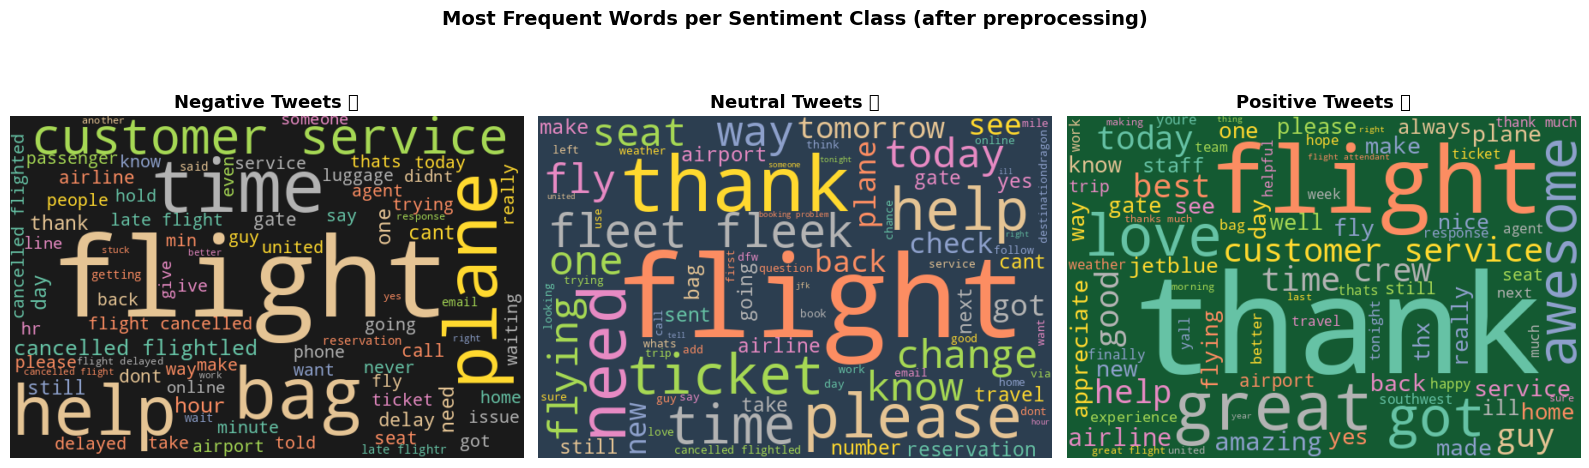

📌 Observation:
Negative tweets feature words like 'delay', 'cancelled', 'hold', 'hour'.
Positive tweets feature words like 'thank', 'great', 'amazing', 'love'.


In [10]:
# ── Word Clouds: Most frequent words per sentiment ────────────────────────────
# This gives us a visual intuition of what words dominate each class

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
titles  = ['Negative Tweets ❌', 'Neutral Tweets ➖', 'Positive Tweets ✅']
labels  = ['negative', 'neutral', 'positive']
bg_cols = ['#1a1a1a', '#2c3e50', '#145a32']

for ax, label, title, bg in zip(axes, labels, titles, bg_cols):
    corpus = ' '.join(df[df['sentiment'] == label]['clean_text'])
    wc = WordCloud(width=600, height=400, background_color=bg,
                   max_words=80, colormap='Set2').generate(corpus)
    ax.imshow(wc, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(title, fontsize=13, fontweight='bold')

plt.suptitle('Most Frequent Words per Sentiment Class (after preprocessing)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('wordclouds.png', dpi=120, bbox_inches='tight')
plt.show()

print("📌 Observation:")
print("Negative tweets feature words like 'delay', 'cancelled', 'hold', 'hour'.")
print("Positive tweets feature words like 'thank', 'great', 'amazing', 'love'.")

---
## Step 3 — Feature Extraction 🔢

Machine learning models cannot work with raw text — they need **numbers**.  
Feature extraction transforms our cleaned text into numerical vectors.

We experiment with **three methods**:

### 3.1 Bag of Words (BoW)
The simplest approach. It creates a vocabulary of all unique words across all tweets,  
then represents each tweet as a vector counting how many times each word appears.

> Example: Vocabulary = ["flight", "love", "delay"]  
> Tweet = "I love this flight" → vector = [1, 1, 0]

**Limitation:** All words are treated equally — common words like "flight" dominate.

### 3.2 TF-IDF (Term Frequency – Inverse Document Frequency)
An improvement over BoW. It assigns **higher weight to rare but meaningful words** and lower weight to very common ones.

> TF = how often a word appears in a tweet  
> IDF = how rare the word is across all tweets  
> TF-IDF = TF × IDF

**This is the most commonly used method in text classification.**

### 3.3 Word Embeddings (GloVe via spaCy)
Instead of counting words, embeddings represent each word as a **dense vector of real numbers** that captures its *meaning*.  
Words with similar meanings have similar vectors (e.g. "good" and "great" are close in vector space).  
We use the average of word vectors across a tweet as its representation.

> This approach captures semantic relationships that BoW and TF-IDF miss.

> **Note:** the embedding approach was implemented but **not evaluated** in the final run, because the spaCy model `en_core_web_md` was unavailable in the Colab session (see the output of Section 3.3). All reported results therefore cover Bag of Words, TF-IDF and DistilBERT only.


In [11]:
# ── Encode labels ─────────────────────────────────────────────────────────────
# We convert string labels to numbers for the models:
#   negative → 0   |   neutral → 1   |   positive → 2

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['label'] = le.fit_transform(df['sentiment'])

print("Label encoding:")
for cls, num in zip(le.classes_, le.transform(le.classes_)):
    print(f"  {cls:10s} → {num}")

Label encoding:
  negative   → 0
  neutral    → 1
  positive   → 2


In [12]:
# ── Train / Test split ────────────────────────────────────────────────────────
# We split data BEFORE feature extraction to avoid data leakage.
# 80% for training, 20% for testing. random_state ensures reproducibility.

X = df['clean_text']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
# stratify=y ensures each split keeps the same class ratio as the full dataset

print(f"Training set : {len(X_train):,} tweets ({len(X_train)/len(X)*100:.0f}%)")
print(f"Test set     : {len(X_test):,}  tweets ({len(X_test)/len(X)*100:.0f}%)")

Training set : 11,712 tweets (80%)
Test set     : 2,928  tweets (20%)


In [13]:
# ── 3.1 Bag of Words ──────────────────────────────────────────────────────────
# max_features=5000 → only keep the top 5000 most frequent words

bow_vectorizer = CountVectorizer(max_features=5000, ngram_range=(1, 2))
# ngram_range=(1,2) includes both single words and word pairs (bigrams)
# e.g. "flight delay" is captured as a single feature — more expressive

X_train_bow = bow_vectorizer.fit_transform(X_train)   # fit on train only!
X_test_bow  = bow_vectorizer.transform(X_test)        # apply same vocab to test

print(f"BoW matrix shape  (train): {X_train_bow.shape}")
print(f"BoW matrix shape  (test) : {X_test_bow.shape}")
print(f"Vocabulary size           : {len(bow_vectorizer.vocabulary_):,} features")

BoW matrix shape  (train): (11712, 5000)
BoW matrix shape  (test) : (2928, 5000)
Vocabulary size           : 5,000 features


In [14]:
# ── 3.2 TF-IDF ───────────────────────────────────────────────────────────────
# Same parameters as BoW but uses TF-IDF weighting instead of raw counts

tfidf_vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf  = tfidf_vectorizer.transform(X_test)

print(f"TF-IDF matrix shape (train): {X_train_tfidf.shape}")
print(f"TF-IDF matrix shape (test) : {X_test_tfidf.shape}")

# Show the top 15 words with highest average TF-IDF weight
feature_names = tfidf_vectorizer.get_feature_names_out()
mean_tfidf    = X_train_tfidf.mean(axis=0).A1
top15_idx     = mean_tfidf.argsort()[::-1][:15]

print("\nTop 15 highest-weighted TF-IDF features (unigrams + bigrams):")
for i in top15_idx:
    print(f"  {feature_names[i]:25s}  score = {mean_tfidf[i]:.4f}")

TF-IDF matrix shape (train): (11712, 5000)
TF-IDF matrix shape (test) : (2928, 5000)

Top 15 highest-weighted TF-IDF features (unigrams + bigrams):
  flight                     score = 0.0363
  thanks                     score = 0.0201
  thank                      score = 0.0163
  get                        score = 0.0157
  hour                       score = 0.0138
  service                    score = 0.0123
  cancelled                  score = 0.0122
  customer                   score = 0.0119
  time                       score = 0.0119
  help                       score = 0.0115
  bag                        score = 0.0103
  plane                      score = 0.0102
  please                     score = 0.0091
  hold                       score = 0.0090
  need                       score = 0.0090


In [20]:
# ── 3.3 Word Embeddings (GloVe via spaCy) ────────────────────────────────────
# spaCy has pre-trained English word vectors (GloVe trained on web data).
# For each tweet, we average the vectors of all its words.
# This gives us a fixed-size 96-dimensional vector per tweet.

# NOTE: Run this first in your terminal if you haven't yet:
#   python -m spacy download en_core_web_md

import spacy

try:
    nlp = spacy.load('en_core_web_md')   # medium model — has 20k word vectors
    SPACY_AVAILABLE = True
    print("✅ spaCy en_core_web_md loaded successfully")
except OSError:
    print("⚠️  spaCy en_core_web_md not found.")
    print("    Run: python -m spacy download en_core_web_md")
    print("    We will skip the embeddings model in this run.")
    SPACY_AVAILABLE = False

if SPACY_AVAILABLE:
    def tweet_to_vector(text):
        """Convert a tweet string to its average GloVe word vector."""
        doc = nlp(text)
        if doc.vector_norm == 0:           # all words are OOV (out of vocabulary)
            return np.zeros(nlp.vocab.vectors_length)
        return doc.vector                  # average vector across all tokens

    X_train_emb = np.vstack(X_train.apply(tweet_to_vector).values)
    X_test_emb  = np.vstack(X_test.apply(tweet_to_vector).values)
    print(f"Embedding matrix shape (train): {X_train_emb.shape}")
    print(f"Embedding matrix shape (test) : {X_test_emb.shape}")

⚠️  spaCy en_core_web_md not found.
    Run: python -m spacy download en_core_web_md
    We will skip the embeddings model in this run.


---
## Step 4 — Model Training 🤖

We train and compare **three models** across different feature sets:

| Model | Type | Why we use it |
|---|---|---|
| **Logistic Regression** | Traditional ML | Simple, fast, good baseline for text classification |
| **SVM (LinearSVC)** | Traditional ML | Strong performance on high-dimensional text data |
| **BERT (DistilBERT)** | Transformer (Advanced) | Understands word context; state-of-the-art in NLP |

### Why multiple models?
Each model has trade-offs between **accuracy**, **speed**, and **complexity**.  
By comparing them, we learn which one best suits our task and our resources.

> 💡 **Logistic Regression** uses a mathematical function to separate classes in the feature space.  
> 💡 **SVM** finds the best boundary (hyperplane) that maximises the margin between classes.  
> 💡 **BERT** reads the full sentence bidirectionally and captures context — "not great" is understood as negative.

In [21]:
# ── Helper function: evaluate and display results ─────────────────────────────

results = []   # we'll store all results here for the final comparison

def evaluate_model(model_name, y_true, y_pred, feature_type):
    """
    Prints a full classification report, plots a confusion matrix,
    and stores the accuracy in the results list.
    """
    acc = accuracy_score(y_true, y_pred)
    print(f"\n{'='*60}")
    print(f"  Model       : {model_name}")
    print(f"  Features    : {feature_type}")
    print(f"  Accuracy    : {acc*100:.2f}%")
    print(f"{'='*60}")
    print(classification_report(y_true, y_pred,
                                 target_names=['negative', 'neutral', 'positive']))

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(5, 4))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                   display_labels=['negative', 'neutral', 'positive'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'Confusion Matrix\n{model_name} | {feature_type}', fontsize=11)
    plt.tight_layout()
    plt.savefig(f'cm_{model_name.replace(" ","_")}_{feature_type}.png',
                dpi=100, bbox_inches='tight')
    plt.show()

    # Store result
    results.append({'Model': model_name, 'Features': feature_type, 'Accuracy': acc})

print("✅ Helper function ready.")

✅ Helper function ready.



  Model       : Logistic Regression
  Features    : Bag of Words
  Accuracy    : 78.28%
              precision    recall  f1-score   support

    negative       0.85      0.88      0.86      1835
     neutral       0.60      0.61      0.61       620
    positive       0.75      0.64      0.69       473

    accuracy                           0.78      2928
   macro avg       0.73      0.71      0.72      2928
weighted avg       0.78      0.78      0.78      2928



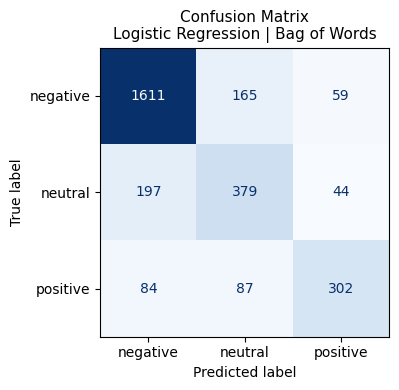

In [16]:
# ── 4.1 Logistic Regression + BoW ────────────────────────────────────────────
# C=1.0 is the regularisation strength (default). max_iter=1000 ensures convergence.

lr_bow = LogisticRegression(C=1.0, max_iter=1000, random_state=42)
lr_bow.fit(X_train_bow, y_train)
y_pred_lr_bow = lr_bow.predict(X_test_bow)

evaluate_model('Logistic Regression', y_test, y_pred_lr_bow, 'Bag of Words')


  Model       : Logistic Regression
  Features    : TF-IDF
  Accuracy    : 78.38%
              precision    recall  f1-score   support

    negative       0.81      0.94      0.87      1835
     neutral       0.65      0.50      0.56       620
    positive       0.82      0.57      0.67       473

    accuracy                           0.78      2928
   macro avg       0.76      0.67      0.70      2928
weighted avg       0.78      0.78      0.77      2928



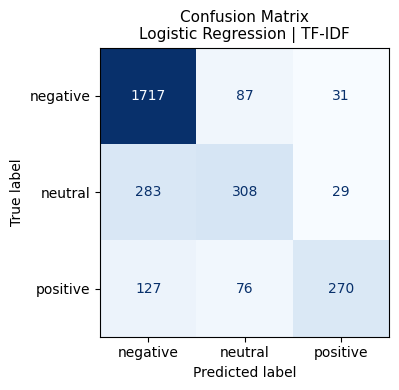

In [22]:
# ── 4.2 Logistic Regression + TF-IDF ─────────────────────────────────────────

lr_tfidf = LogisticRegression(C=1.0, max_iter=1000, random_state=42)
lr_tfidf.fit(X_train_tfidf, y_train)
y_pred_lr_tfidf = lr_tfidf.predict(X_test_tfidf)

evaluate_model('Logistic Regression', y_test, y_pred_lr_tfidf, 'TF-IDF')


  Model       : SVM (LinearSVC)
  Features    : TF-IDF
  Accuracy    : 78.35%
              precision    recall  f1-score   support

    negative       0.84      0.89      0.87      1835
     neutral       0.61      0.58      0.59       620
    positive       0.76      0.62      0.68       473

    accuracy                           0.78      2928
   macro avg       0.74      0.70      0.71      2928
weighted avg       0.78      0.78      0.78      2928



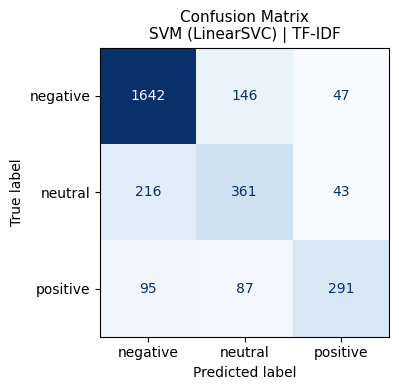

In [23]:
# ── 4.3 SVM (LinearSVC) + TF-IDF ─────────────────────────────────────────────
# LinearSVC is a fast version of SVM designed for large text datasets.
# It is a common strong baseline for text classification.

svm_tfidf = LinearSVC(C=1.0, max_iter=2000, random_state=42)
svm_tfidf.fit(X_train_tfidf, y_train)
y_pred_svm_tfidf = svm_tfidf.predict(X_test_tfidf)

evaluate_model('SVM (LinearSVC)', y_test, y_pred_svm_tfidf, 'TF-IDF')

In [25]:
# ── 4.4 SVM + Word Embeddings (GloVe) ────────────────────────────────────────
# This uses the semantic embedding vectors instead of word frequency counts.

if SPACY_AVAILABLE:
    svm_emb = LinearSVC(C=1.0, max_iter=2000, random_state=42)
    svm_emb.fit(X_train_emb, y_train)
    y_pred_svm_emb = svm_emb.predict(X_test_emb)

    evaluate_model('SVM (LinearSVC)', y_test, y_pred_svm_emb, 'GloVe Embeddings')
else:
    print("⚠️  Skipping SVM + Embeddings because spaCy model is not available.")

⚠️  Skipping SVM + Embeddings because spaCy model is not available.


### 4.5 Advanced Model: DistilBERT (Transformer-Based)

**BERT** (Bidirectional Encoder Representations from Transformers) is a state-of-the-art language model developed by Google in 2018.  
We use **DistilBERT**, a smaller and faster version that retains ~97% of BERT's performance.

**Why is BERT special?**
- It reads each word **in context** — the meaning of "fly" in "I want to fly" vs "my flight didn't fly on time" is different.
- Traditional models treat each word independently. BERT understands **relationships between words**.
- It was pre-trained on millions of documents, so it already understands English deeply.

**What is fine-tuning?**  
We take the pre-trained DistilBERT model and continue training it on our specific airline tweets dataset. This process is called **fine-tuning** — we adapt the general language understanding of BERT to our specific classification task.

> ⚠️ This step requires a GPU for fast training (Google Colab provides a free GPU).  
> On CPU it will be slow but will still run correctly. We use only 3 training epochs to keep it manageable.

In [26]:
# ── 4.5 DistilBERT Fine-Tuning ────────────────────────────────────────────────
# Requirements: pip install transformers torch

import torch
from torch.utils.data import Dataset, DataLoader
from transformers import DistilBertTokenizerFast, DistilBertForSequenceClassification
from torch.optim import AdamW
from sklearn.metrics import accuracy_score

# Detect device (GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# ── Dataset class ─────────────────────────────────────────────────────────────
class TweetDataset(Dataset):
    """
    Custom PyTorch Dataset.
    Wraps our tweet texts and labels so the DataLoader can batch them.
    """
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts     = texts.tolist()
        self.labels    = labels.tolist()
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        return {
            'input_ids':      encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'labels':         torch.tensor(self.labels[idx], dtype=torch.long)
        }


# ── Load tokeniser and model ──────────────────────────────────────────────────
MODEL_NAME  = 'distilbert-base-uncased'
NUM_CLASSES = 3   # negative, neutral, positive

tokenizer = DistilBertTokenizerFast.from_pretrained(MODEL_NAME)

# NOTE: DistilBERT is fed the same preprocessed text (clean_text) as the classical models,
# i.e. after stop-word removal and lemmatisation. See Section 6.4 for why this is a limitation.
X_train_raw = X_train   # preprocessed clean_text (stop words removed, lemmatised)
X_test_raw  = X_test    # preprocessed clean_text; BERT's tokeniser sub-word tokenises it

# Create datasets
train_dataset = TweetDataset(X_train_raw, y_train.reset_index(drop=True), tokenizer)
test_dataset  = TweetDataset(X_test_raw,  y_test.reset_index(drop=True),  tokenizer)

# Create data loaders (batch_size=32 is standard for fine-tuning)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=64, shuffle=False)

print(f"✅ Tokeniser loaded | Training batches: {len(train_loader)} | Test batches: {len(test_loader)}")

Using device: cuda


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

✅ Tokeniser loaded | Training batches: 366 | Test batches: 46


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Epoch 1/3 | Batch 50/366 | Loss: 0.8274
  Epoch 1/3 | Batch 100/366 | Loss: 0.5331
  Epoch 1/3 | Batch 150/366 | Loss: 0.7006
  Epoch 1/3 | Batch 200/366 | Loss: 0.8825
  Epoch 1/3 | Batch 250/366 | Loss: 0.4799
  Epoch 1/3 | Batch 300/366 | Loss: 0.4478
  Epoch 1/3 | Batch 350/366 | Loss: 0.4869

✅ Epoch 1 complete — Avg Loss: 0.6098

  Epoch 2/3 | Batch 50/366 | Loss: 0.6764
  Epoch 2/3 | Batch 100/366 | Loss: 0.4551
  Epoch 2/3 | Batch 150/366 | Loss: 0.4493
  Epoch 2/3 | Batch 200/366 | Loss: 0.3880
  Epoch 2/3 | Batch 250/366 | Loss: 0.3420
  Epoch 2/3 | Batch 300/366 | Loss: 0.3058
  Epoch 2/3 | Batch 350/366 | Loss: 0.3915

✅ Epoch 2 complete — Avg Loss: 0.4416

  Epoch 3/3 | Batch 50/366 | Loss: 0.2124
  Epoch 3/3 | Batch 100/366 | Loss: 0.1918
  Epoch 3/3 | Batch 150/366 | Loss: 0.4621
  Epoch 3/3 | Batch 200/366 | Loss: 0.3492
  Epoch 3/3 | Batch 250/366 | Loss: 0.3299
  Epoch 3/3 | Batch 300/366 | Loss: 0.3170
  Epoch 3/3 | Batch 350/366 | Loss: 0.5673

✅ Epoch 3 complete 

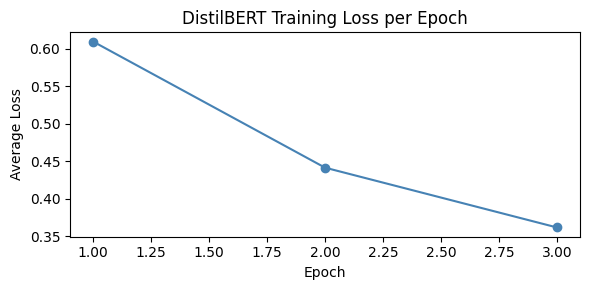

In [27]:
# ── Fine-tune DistilBERT ──────────────────────────────────────────────────────
# We train for 3 epochs. One epoch = the model sees all training data once.
from transformers import get_linear_schedule_with_warmup
EPOCHS    = 3
LR        = 2e-5   # standard learning rate for BERT fine-tuning

model = DistilBertForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=NUM_CLASSES
)
model = model.to(device)

# Optimiser and learning rate scheduler
optimizer = AdamW(model.parameters(), lr=LR)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer, num_warmup_steps=0, num_training_steps=total_steps
)

train_losses = []

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0

    for batch_idx, batch in enumerate(train_loader):
        input_ids      = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels         = batch['labels'].to(device)

        optimizer.zero_grad()
        outputs = model(input_ids=input_ids,
                        attention_mask=attention_mask,
                        labels=labels)
        loss = outputs.loss
        loss.backward()

        # Clip gradients to prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()
        scheduler.step()
        total_loss += loss.item()

        if (batch_idx + 1) % 50 == 0:
            print(f"  Epoch {epoch+1}/{EPOCHS} | Batch {batch_idx+1}/{len(train_loader)} "
                  f"| Loss: {loss.item():.4f}")

    avg_loss = total_loss / len(train_loader)
    train_losses.append(avg_loss)
    print(f"\n✅ Epoch {epoch+1} complete — Avg Loss: {avg_loss:.4f}\n")

# Plot training loss
plt.figure(figsize=(6, 3))
plt.plot(range(1, EPOCHS+1), train_losses, marker='o', color='steelblue')
plt.title('DistilBERT Training Loss per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Average Loss')
plt.tight_layout()
plt.savefig('bert_training_loss.png', dpi=100, bbox_inches='tight')
plt.show()


  Model       : DistilBERT
  Features    : Transformer
  Accuracy    : 79.78%
              precision    recall  f1-score   support

    negative       0.87      0.88      0.87      1835
     neutral       0.64      0.62      0.63       620
    positive       0.72      0.70      0.71       473

    accuracy                           0.80      2928
   macro avg       0.74      0.73      0.74      2928
weighted avg       0.80      0.80      0.80      2928



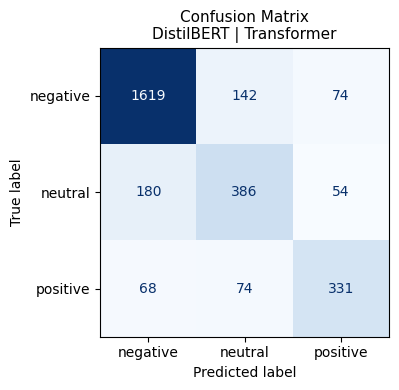

In [28]:
# ── Evaluate DistilBERT on the test set ───────────────────────────────────────

model.eval()
all_preds  = []
all_labels = []

with torch.no_grad():
    for batch in test_loader:
        input_ids      = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels         = batch['labels'].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        preds   = torch.argmax(outputs.logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

y_pred_bert = np.array(all_preds)
y_true_bert = np.array(all_labels)

evaluate_model('DistilBERT', y_true_bert, y_pred_bert, 'Transformer')

---
## Step 5 — Evaluation & Comparison 📊

We now compare all models side by side.

### Metrics explained:
- **Accuracy** — % of tweets correctly classified (overall)
- **Precision** — Of all tweets predicted as "positive", how many were actually positive? (reduces false alarms)
- **Recall** — Of all actually positive tweets, how many did we correctly find? (reduces misses)
- **F1-Score** — Harmonic mean of Precision and Recall. Balances both concerns. Especially useful for imbalanced datasets.

> 💡 Because our dataset is imbalanced (many more negative tweets), **F1-Score is more informative than raw accuracy**.

              Model    Features  Accuracy %
         DistilBERT Transformer       79.78
Logistic Regression      TF-IDF       78.38
    SVM (LinearSVC)      TF-IDF       78.35


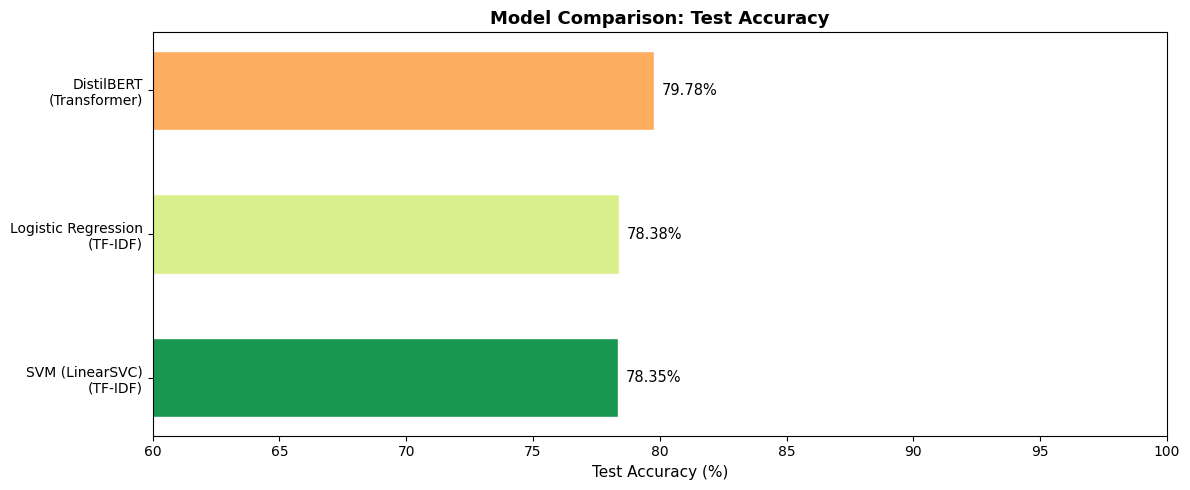

In [29]:
# ── Final model comparison bar chart ─────────────────────────────────────────

results_df = pd.DataFrame(results).sort_values('Accuracy', ascending=False)
results_df['Accuracy %'] = (results_df['Accuracy'] * 100).round(2)
results_df['Label'] = results_df['Model'] + '\n(' + results_df['Features'] + ')'

print(results_df[['Model', 'Features', 'Accuracy %']].to_string(index=False))

# Bar chart
fig, ax = plt.subplots(figsize=(12, 5))
bar_colors = plt.cm.RdYlGn(np.linspace(0.3, 0.9, len(results_df)))
bars = ax.barh(results_df['Label'], results_df['Accuracy %'],
               color=bar_colors, edgecolor='white', height=0.55)

for bar, val in zip(bars, results_df['Accuracy %']):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            f'{val:.2f}%', va='center', fontsize=10.5)

ax.set_xlabel('Test Accuracy (%)', fontsize=11)
ax.set_title('Model Comparison: Test Accuracy', fontsize=13, fontweight='bold')
ax.set_xlim(60, 100)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=120, bbox_inches='tight')
plt.show()

---
## Step 6 — Analysis & Discussion 🔍

### 6.1 Results (test set: 2,928 tweets, single stratified 80/20 split)

| Model | Features | Accuracy | Macro-F1 |
|---|---|---|---|
| Logistic Regression | Bag of Words | 78.28% | 0.72 |
| Logistic Regression | TF-IDF | 78.38% | 0.70 |
| SVM (LinearSVC) | TF-IDF | 78.35% | 0.71 |
| DistilBERT (fine-tuned, 3 epochs) | Sub-word tokens | **79.78%** | **0.74** |

A model that always predicts "negative" would score 62.7% accuracy on this test set. The GloVe-embedding model was not evaluated (see the note in Section 3.3).

### 6.2 Key findings

**DistilBERT is best on both metrics, but the margin is small.** It leads the best classical model by about 1.4 accuracy points. With 2,928 test tweets, a rough 95% binomial interval on each accuracy is about ±1.5 points, so one train/test split cannot establish that the gap is significant.

**The three classical models are indistinguishable in accuracy (78.28–78.38%).** In particular, TF-IDF did not beat Bag of Words here, and the SVM did not beat Logistic Regression. Bag of Words even has the higher macro-F1 (0.72 vs 0.70), because the TF-IDF logistic regression recalls fewer neutral tweets (0.50 vs 0.61).

**The neutral class is the hardest for every model.** Per-class F1 is 0.86–0.87 for negative, 0.67–0.71 for positive and only 0.56–0.63 for neutral. DistilBERT's advantage is concentrated on the neutral and positive classes.

**The most informative words are intuitive** (e.g. *hour*, *worst*, *delayed* for negative; *great*, *thanks*, *awesome* for positive). The neutral class is dominated by topical or named tokens (e.g. *avgeek*, *atlanta*), which suggests it is defined more by topic than by sentiment.

### 6.3 Error analysis

SVM + TF-IDF misclassified 634 of 2,928 tweets (21.7%). Reading the sample above, some errors look like **ambiguous or noisy labels** (e.g. a "thanks getting back…" tweet labelled negative), and others depend on negation or tone that word-count features cannot represent.

### 6.4 Limitations

1. **Single split, single seed.** No cross-validation and no confidence intervals, so small differences between models should not be over-interpreted.
2. **Stop-word removal also removes negations.** NLTK's English list contains words such as "not", so "not great" becomes "great" before the models see it.
3. **DistilBERT was fed the same preprocessed text** (stop words removed, lemmatised), not the raw tweets it was pre-trained on. This probably understates its potential.
4. **GloVe embeddings were not evaluated** because the spaCy model was unavailable in the runtime.
5. **No hyper-parameter tuning.** Default regularisation (C=1.0), 3 epochs and a learning rate of 2e-5 were used throughout.
6. **No explicit imbalance handling** beyond a stratified split and macro-F1 reporting (no class weights or resampling).
7. The dataset's own labelling-confidence column (`airline_sentiment_confidence`) was not used.

### 6.5 Trade-offs

| Model | Compute | Interpretability |
|---|---|---|
| Logistic Regression | CPU, fast to train | High (coefficients can be inspected, see the word plots) |
| SVM (LinearSVC) | CPU, fast to train | Medium |
| DistilBERT | GPU used in this run (CUDA); ~268 MB of pre-trained weights | Low |

For a use case that needs cheap, fast, explainable predictions, a TF-IDF linear model is a reasonable default given how close the accuracies are. DistilBERT earns its cost only if the extra points on neutral and positive tweets matter.

### 6.6 Next steps

- Re-run DistilBERT on **raw tweets** (no stop-word removal) and keep negations in the classical pipeline.
- Evaluate the **GloVe** model with the spaCy vectors installed.
- Use **stratified k-fold cross-validation** and report mean ± standard deviation.
- Tune hyper-parameters and try **class weights**.


In [30]:
# ── 6.3 Qualitative analysis: inspect misclassified examples ─────────────────
# Let's look at some tweets a representative classical model (SVM + TF-IDF) got wrong.
# This tells us WHY the model struggles.

test_df = pd.DataFrame({
    'text'      : X_test.values,
    'true_label': le.inverse_transform(y_test),
    'predicted' : le.inverse_transform(y_pred_svm_tfidf)
})

misclassified = test_df[test_df['true_label'] != test_df['predicted']]

print(f"Total misclassified by SVM+TF-IDF: {len(misclassified)} / {len(test_df)}")
print(f"Error rate: {len(misclassified)/len(test_df)*100:.1f}%")
print("\n--- Sample misclassified tweets (interesting failure cases) ---")
np.random.seed(7)
sample = misclassified.sample(min(10, len(misclassified)), random_state=7)
for _, row in sample.iterrows():
    print(f"\n  Tweet     : {row['text'][:100]}")
    print(f"  True label: {row['true_label']:10s}  |  Predicted: {row['predicted']}")

Total misclassified by SVM+TF-IDF: 634 / 2928
Error rate: 21.7%

--- Sample misclassified tweets (interesting failure cases) ---

  Tweet     : helping step game tindertips tinderchamp
  True label: neutral     |  Predicted: negative

  Tweet     : still air deicing plane ill miss connect customer service helpfulim hoping catch next flight
  True label: positive    |  Predicted: negative

  Tweet     : gate truck come
  True label: negative    |  Predicted: neutral

  Tweet     : youd love see girl get inspired becoming pilot free albuquerque event
  True label: neutral     |  Predicted: positive

  Tweet     : good ideasshe traveling todayat airport need petition faa regarding silly name change rule
  True label: neutral     |  Predicted: negative

  Tweet     : thanks getting back find airline future
  True label: negative    |  Predicted: positive

  Tweet     : need vacation ice
  True label: neutral     |  Predicted: negative

  Tweet     : take look status sitting ord aint cool
 

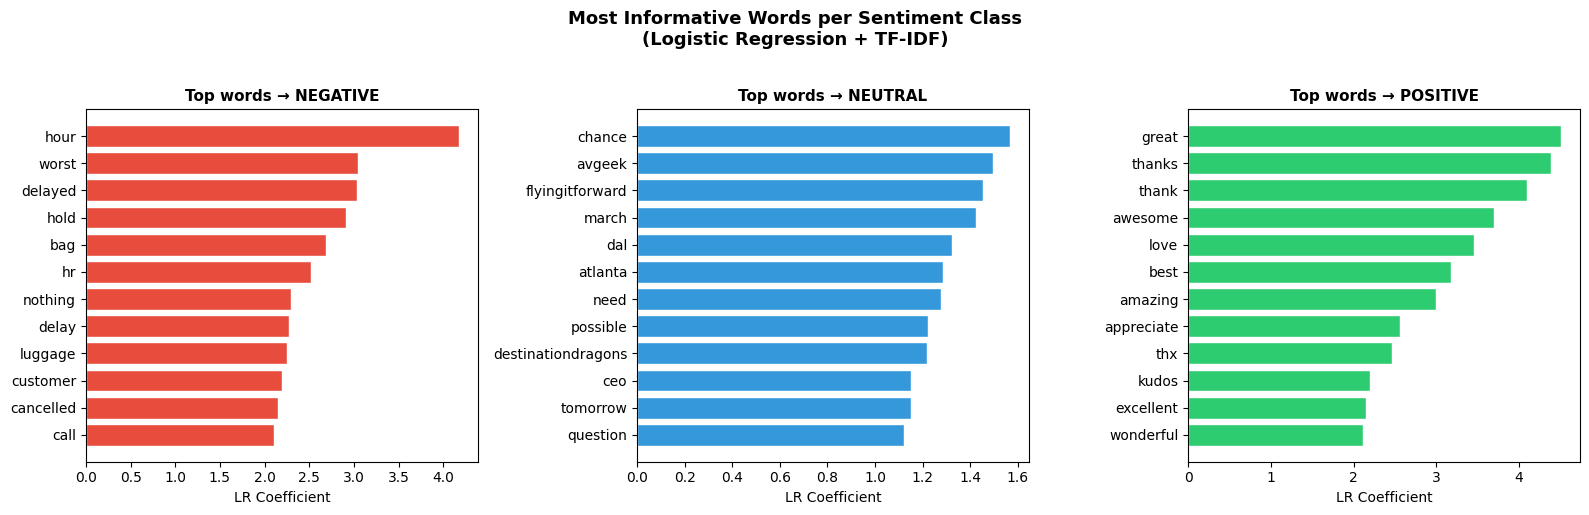


📌 Interpretation: these are the words whose presence most strongly
   pushes the model toward each sentiment class.


In [31]:
# ── 6.4 Most informative features per class (Logistic Regression) ─────────────
# By inspecting the top coefficients, we see which words most strongly indicate each sentiment.
# This makes the model interpretable.

feature_names = tfidf_vectorizer.get_feature_names_out()
class_labels  = ['negative', 'neutral', 'positive']
TOP_N         = 12

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
palette   = ['#e74c3c', '#3498db', '#2ecc71']

for cls_idx, (ax, label, color) in enumerate(zip(axes, class_labels, palette)):
    coefs     = lr_tfidf.coef_[cls_idx]
    top_idx   = coefs.argsort()[::-1][:TOP_N]
    top_words = [feature_names[i] for i in top_idx]
    top_vals  = [coefs[i] for i in top_idx]

    ax.barh(top_words[::-1], top_vals[::-1], color=color, edgecolor='white')
    ax.set_title(f'Top words → {label.upper()}', fontsize=11, fontweight='bold')
    ax.set_xlabel('LR Coefficient')

plt.suptitle('Most Informative Words per Sentiment Class\n(Logistic Regression + TF-IDF)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('top_features.png', dpi=120, bbox_inches='tight')
plt.show()

print("\n📌 Interpretation: these are the words whose presence most strongly")
print("   pushes the model toward each sentiment class.")

---
## 🏁 Project Summary

| Phase | What was done |
|---|---|
| **Data** | US Airline Twitter dataset (14,640 labelled tweets, 3 classes) |
| **Preprocessing** | Removed mentions, URLs, HTML entities, punctuation and numbers; lowercased; tokenised; removed stop words and very short tokens; lemmatised |
| **Features** | Bag of Words and TF-IDF (unigrams + bigrams, 5,000 features). GloVe embeddings implemented but not evaluated in the final run |
| **Models** | Logistic Regression (BoW and TF-IDF), SVM (LinearSVC, TF-IDF), fine-tuned DistilBERT |
| **Evaluation** | Accuracy, precision, recall, F1, macro-F1, confusion matrices |
| **Analysis** | Model comparison, error analysis, word-level interpretability, limitations |

*École Centrale Casablanca — NLP Final Project — May 2026*
